In [ ]:
import Pyro4
import numpy as np
import matplotlib.pyplot as plt
import threading
import time
import os
import ntpath
import sys
from pathlib import Path

from lmfit.models import LinearModel

HYDRAHARP_BASE_RES_S = 4e-12

def my_find_nearest(ar, target):
    return int((np.abs(ar - target)).argmin())
import matplotlib



1

In [2]:
# Client/server connection
Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"
Pyro4.config.THREADPOOL_SIZE = 40
Pyro4.config.THREADPOOL_SIZE_MIN = 4

SERVER_URI = "PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9098"
# SERVER_URI = "PYRO:Analysis_g13@127.0.0.1:9099"
URI = SERVER_URI  # Backward-compatible alias for older cells.

try:
    stop_logs.set()
except NameError:
    pass


def analysis_setup(uri=SERVER_URI):
    global analysis_cmd, stop_logs
    analysis_cmd = Pyro4.Proxy(uri)
    stop_logs = threading.Event()

    def log_poller():
        analysis_log = Pyro4.Proxy(uri)
        idx = 0
        progress_active = False
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        sys.stdout.write('\r\033[K')
                        sys.stdout.write(line[1:])
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write('\n')
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as exc:
                if progress_active:
                    sys.stdout.write('\n')
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {exc}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)

    threading.Thread(target=log_poller, daemon=True).start()
    print("------------------ LOG ------------------", flush=True)
    analysis_cmd.ping()
    return analysis_cmd


def re_bin(x, y, n_new_bins_approx):
    n_new_bins_approx = int(n_new_bins_approx)
    if n_new_bins_approx <= 0:
        raise ValueError("n_new_bins_approx must be positive")
    len_new_bins = max(1, len(x) // n_new_bins_approx)
    n_new_bins = len(x) // len_new_bins
    stop = n_new_bins * len_new_bins
    x_rebin = np.mean(np.asarray(x[:stop]).reshape(n_new_bins, len_new_bins), axis=1)
    y_rebin = np.sum(np.asarray(y[:stop]).reshape(n_new_bins, len_new_bins), axis=1)
    return x_rebin, y_rebin


def rebin_plot(tau, hist, n_new_bins=None, ref_range_s=None, x_limit_us=None, y_limit=None,
               title=None, savepath=None, y_offset=0):
    plt.figure(figsize=(10, 2.8))
    if ref_range_s is not None:
        tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
        bg_range = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        plt.plot(tau_rebin * 1e6, h_rebin_detrend / h_0 + y_offset, "-o", markersize=4, label="Normalized detrended coincidences")
        plt.plot(tau_rebin[bg_range[0]:bg_range[1]] * 1e6,
                 h_rebin_detrend[bg_range[0]:bg_range[1]] / h_0 + y_offset,
                 "-o", markersize=4, label="Reference range", color="darkred", alpha=0.5)
        for level, label in [(2 * stdv_h / h_0, r"$\pm 2\sigma$"), (-2 * stdv_h / h_0, None), (0, "Mean")]:
            plt.plot([tau_rebin[0] * 1e6, tau_rebin[-1] * 1e6], [level + y_offset, level + y_offset],
                     color="grey" if level else "lightgrey", label=label)
        plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    else:
        tau_rebin, h_rebin = g2izer(tau, hist, n_new_bins, ref_range_s)
        plt.plot(tau_rebin * 1e6, h_rebin + y_offset, "-o", markersize=4, label="Coincidences per bin")
        plt.ylabel("Coincidences per bin")

    if x_limit_us is not None:
        plt.xlim(-x_limit_us / 50, x_limit_us)
    if y_limit is not None:
        plt.ylim(*y_limit)
    if title is not None:
        bin_size_ns = int((tau_rebin[1] - tau_rebin[0]) * 1e9) if len(tau_rebin) > 1 else 0
        plt.title(f"{title}\nTime delay bin size = {bin_size_ns} ns")
    plt.legend()
    plt.xlabel(r"Time delay $\tau$ (us)")
    plt.tight_layout()
    if savepath is not None:
        plt.savefig(os.path.join(savepath, "classical_analysis.png"), dpi=400)



In [ ]:


analysis_setup()




------------------ LOG ------------------


<Pyro4.core.Proxy at 0x299257f3070; connected IPv4; for PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9098>

PicoHarp analysis server reached.


[ANALYSIS - UTC 2026-06-02 15:47:02] Reading file with name acq_10 in mode A0 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\20260602_testing
[ANALYSIS - UTC 2026-06-02 15:47:58] PicoHarp file C:\Users\SSPDs\Documents\Offline SSPD Data\20260602_testing\acq_10.b: 10040413 records
mode=A0, tau_min=0.08us, tau_max=2000us, bin=40000.0ps
ticks: min=20000, max=500000000, bin=10000, nbins=49998
[decode] 100.0% (10040413/10040413) records
Decoded 9969223 photons in 0.6s; overflow records=71190; ch0=9954227, ch1=14996
Selected mode=A0: ref=9954227, stop=9954227; using 7 workers.
[correlate] 100.0% done, elapsed 4.7s ETA 0.0s
Correlation done in 4.7s; coincidences=3565992929
Correlation done.
[classical] PicoHarp file C:\Users\SSPDs\Documents\Offline SSPD Data\20260602_testing\acq_10.b: 10040413 records
[classical] dt=10 ms, chunk=1 min, bins/chunk=6000
[classical] processed 100.0% (10040413/10040413) records
[classical] computing FFT autocorrelation of classical bins...
[classical] save

# All analysis in one:

In [4]:

def load_or_create_classical_bins(filepath, bin_width_ms=20, chunk_minutes=72,
                                  include_channels=None, force_recompute=False,
                                  show_progress=True):
    classical_folder = str(Path(filepath).with_suffix('')) + "_classical_bins"
    if not force_recompute and Path(classical_folder).exists():
        existing = analysis_cmd.read_existing_classical(
            classical_folder,
            tau_bin_ms=bin_width_ms,
            return_autocorr=True,
        )
        if existing[0]:
            return existing

    classical_folder, _ = analysis_cmd.correlate_b_file_classical(
        filepath=str(filepath),
        tau_bin_ms=bin_width_ms,
        chunk_minutes=chunk_minutes,
        include_channels=include_channels,
        show_progress=show_progress,
        compute_autocorr=True,
    )
    return analysis_cmd.read_existing_classical(
        classical_folder,
        tau_bin_ms=bin_width_ms,
        return_autocorr=True,
    )


def plot_classical_counts(classical_data, title=None, max_chunks=None, histogram_bins="auto",
                          y_lims=None, savepath=None,ac_xlim_s=None):
    if len(classical_data) == 9:
        counts_list, dt_s_list, chunk_minutes_list, chunk_index_list, t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx, saved_autocorr = classical_data
    else:
        counts_list, dt_s_list, chunk_minutes_list, chunk_index_list, t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = classical_data
        saved_autocorr = None

    if not counts_list:
        raise ValueError("No classical bins were found for the requested bin width.")

    if max_chunks is not None:
        counts_list = counts_list[:max_chunks]
        dt_s_list = dt_s_list[:max_chunks]
        chunk_index_list = chunk_index_list[:max_chunks]

    times = []
    counts = []
    elapsed = 0.0
    for chunk_counts, dt_s in zip(counts_list, dt_s_list):
        chunk_counts = np.asarray(chunk_counts)
        t = elapsed + np.arange(chunk_counts.size) * dt_s
        times.append(t)
        counts.append(chunk_counts)
        elapsed = t[-1] + dt_s if t.size else elapsed

    time_s = np.concatenate(times)
    count_values = np.concatenate(counts)
    nonzero_mask = count_values > 0
    nonzero_counts = count_values[nonzero_mask]
    bin_width_s = dt_s_list[0]
    bin_width_ms = bin_width_s * 1e3

    if nonzero_counts.size:
        first_nonzero = int(np.argmax(nonzero_mask))
        last_nonzero = int(len(nonzero_mask) - np.argmax(nonzero_mask[::-1]))
        time_plot_min = time_s[first_nonzero:last_nonzero] / 60.0
        count_plot_values = count_values[first_nonzero:last_nonzero]
    else:
        time_plot_min = time_s / 60.0
        count_plot_values = count_values

    if saved_autocorr is not None:
        autocorr_lag_s = np.asarray(saved_autocorr["lag_s"])
        autocorr = np.asarray(saved_autocorr["autocorr"])
    else:
        signal = count_plot_values.astype(float)
        if signal.size > 1 and np.mean(signal) != 0:
            signal = (signal - np.mean(signal)) / np.mean(signal)
            n = signal.size
            nfft = 1 << (2 * n - 2).bit_length()
            spectrum = np.fft.rfft(signal, n=nfft)
            raw_ac = np.fft.irfft(spectrum * np.conjugate(spectrum), n=nfft)[:n]
            unbiased_norm = np.arange(n, 0, -1)
            autocorr = raw_ac / unbiased_norm
            if autocorr[0] != 0:
                autocorr = autocorr / autocorr[0]
            autocorr_lag_s = np.arange(autocorr.size) * bin_width_s
        else:
            autocorr_lag_s = np.array([])
            autocorr = np.array([])

    if ac_xlim_s is not None:
        lag_mask = autocorr_lag_s <= ac_xlim_s
        autocorr_lag_plot = autocorr_lag_s[lag_mask]
        autocorr_plot = autocorr[lag_mask]
    else:
        autocorr_lag_plot = autocorr_lag_s
        autocorr_plot = autocorr

    fig, (ax_trace, ax_hist, ax_ac) = plt.subplots(
        1,
        3,
        figsize=(13.5, 3.2),
        width_ratios=(4.2, 1.15, 1.9),
    )

    ax_trace.plot(time_plot_min, count_plot_values, linewidth=0.8)
    ax_trace.set_xlabel("Measurement time (min)")
    ax_trace.set_ylabel(f"Counts per {bin_width_ms:g} ms bin")
    if y_lims is not None:
        ax_trace.set_ylim(y_lims)
    if title is not None:
        ax_trace.set_title(title)

    if nonzero_counts.size:
        ax_hist.hist(nonzero_counts, bins=histogram_bins, orientation="horizontal", color="0.35")
    ax_hist.set_xlabel("Occurrences")
    ax_hist.tick_params(axis="y", labelleft=False)
    ax_hist.grid(axis="x", alpha=0.25)
    if y_lims is not None:
        ax_hist.set_ylim(y_lims)
    else:
        ax_hist.set_ylim(ax_trace.get_ylim())

    if autocorr_plot.size:
        ax_ac.plot(autocorr_lag_plot, autocorr_plot, "-o", markersize = 1, linewidth=1.0)
        ax_ac.axhline(0, color="lightgrey", zorder=0)
    ax_ac.set_xlabel("Lag (s)")
    ax_ac.set_ylabel("Autocorr.")
    ax_ac.grid(alpha=0.25)

    fig.tight_layout()
    if savepath is not None:
        fig.savefig(os.path.join(savepath, "classical_analysis.png"), dpi=400)
    return {
        "time_s": time_s,
        "time_plot_min": time_plot_min,
        "counts": count_values,
        "counts_plot": count_plot_values,
        "nonzero_counts": nonzero_counts,
        "autocorr_lag_s": autocorr_lag_s,
        "autocorr": autocorr,
        "saved_autocorr": saved_autocorr,
        "figure": fig,
        "trace_axis": ax_trace,
        "hist_axis": ax_hist,
        "autocorr_axis": ax_ac,
    }


def analyze_all(paths, ratio_g2_bins=100, ref_range_s=(80e-3, 100e-3),
                correlation_mode="X01", x_limit_us=None, y_limit=None,
                title=None, savepath=None, verbose=True,
                plot_classical=True, classical_bin_width_ms=20,
                classical_chunk_minutes=72, force_classical_recompute=False):
    """
    Load an existing HydraHarp correlation histogram, plot normalized g2 - 1,
    and optionally plot classical count bins versus measurement time.
    """
    base, dataset_name, filename = paths
    filepath = Path(base) / filename
    histogram_name = filename[:-2]
    plot_title = title or dataset_name.strip("\\").replace("\\", "_")

    hist, tau, params = analysis_cmd.read_existing(base, mode=correlation_mode, name=histogram_name)
    n_new_bins = max(1, int(len(tau) / ratio_g2_bins))
    tau_rebin, hist_detrended, hist_std, hist_baseline = g2izer(
        tau,
        hist,
        n_new_bins=n_new_bins,
        ref_range_s=ref_range_s,
        verbose=verbose,
    )

    # g2izer returns the detrended numerator. Divide by the baseline to get g2 - 1.
    g2_minus_1 = hist_detrended / hist_baseline
    ref_start = my_find_nearest(tau_rebin, ref_range_s[0])
    ref_stop = my_find_nearest(tau_rebin, ref_range_s[1])

    fig_g2, ax_g2 = plt.subplots(figsize=(10, 3.2))
    ax_g2.plot(tau_rebin * 1e6, g2_minus_1, "-o", markersize=4, label=r"$g^{(2)}(\tau)-1$")
    ax_g2.plot(
        tau_rebin[ref_start:ref_stop] * 1e6,
        g2_minus_1[ref_start:ref_stop],
        "-o",
        markersize=4,
        color="darkred",
        alpha=0.55,
        label="Reference range",
    )
    ax_g2.axhline(0, color="lightgrey", zorder=0)
    ax_g2.axhline(2 * hist_std / hist_baseline, color="grey", zorder=0, label=r"$\pm 2\sigma$")
    ax_g2.axhline(-2 * hist_std / hist_baseline, color="grey", zorder=0)

    if x_limit_us is not None:
        ax_g2.set_xlim(-x_limit_us / 50, x_limit_us)
    if y_limit is not None:
        ax_g2.set_ylim(*y_limit)

    bin_size_ns = (tau_rebin[1] - tau_rebin[0]) * 1e9 if len(tau_rebin) > 1 else np.nan
    ax_g2.set_title(f"{plot_title}\nTime delay bin size = {bin_size_ns:.3g} ns")
    ax_g2.set_xlabel(r"Time delay $\tau$ (us)")
    ax_g2.set_ylabel(r"$g^{(2)}(\tau) - 1$")
    ax_g2.legend()
    fig_g2.tight_layout()

    if savepath is not None:
        fig_g2.savefig(savepath, dpi=300)
    classical_result = None
    classical_plot = None
    if plot_classical:
        classical_result = load_or_create_classical_bins(
            filepath,
            bin_width_ms=classical_bin_width_ms,
            chunk_minutes=classical_chunk_minutes,
            force_recompute=force_classical_recompute,
            show_progress=True,
        )
        classical_plot = plot_classical_counts(
            classical_result,
            title=f"{plot_title}\nClassical bins, {classical_bin_width_ms:g} ms",
        )

    return {
        "tau": tau,
        "hist": hist,
        "tau_rebin": tau_rebin,
        "hist_detrended": hist_detrended,
        "g2_minus_1": g2_minus_1,
        "hist_std": hist_std,
        "hist_baseline": hist_baseline,
        "params": params,
        "g2_figure": fig_g2,
        "g2_axis": ax_g2,
        "classical_data": classical_result,
        "classical_plot": classical_plot,
    }



def g2izer(tau, hist, n_new_bins=None, ref_range_s=None, verbose=True, outlier_sigma=7):
    tau = np.asarray(tau, dtype=float)
    hist = np.asarray(hist)

    if n_new_bins is not None:
        if verbose:
            print(f"Rebinning from {len(tau):d} to {int(n_new_bins):d}")
        tau_rebin, h_rebin = re_bin(tau, hist, int(n_new_bins))
    else:
        if verbose:
            print("Not rebinning")
        tau_rebin, h_rebin = tau, hist

    if len(tau_rebin) > 1 and verbose:
        print(f"Bin size {((tau_rebin[1] - tau_rebin[0]) * 1e9):.3g} ns")

    std_raw = np.std(h_rebin)
    if std_raw > 0:
        keep = np.abs(h_rebin - np.mean(h_rebin)) < outlier_sigma * std_raw
        tau_rebin = tau_rebin[keep]
        h_rebin = h_rebin[keep]

    if ref_range_s is None:
        return tau_rebin, h_rebin

    if len(ref_range_s) != 2:
        raise ValueError("ref_range_s must contain exactly two values in seconds")

    lo, hi = sorted(float(v) for v in ref_range_s)
    bg_start = my_find_nearest(tau_rebin, lo)
    bg_stop = my_find_nearest(tau_rebin, hi)
    if bg_stop <= bg_start:
        raise ValueError("ref_range_s does not select a non-empty background region")

    hist_bg = h_rebin[bg_start:bg_stop]
    tau_bg = tau_rebin[bg_start:bg_stop]
    h_0 = float(np.mean(hist_bg))
    if h_0 == 0:
        raise ValueError("Background mean is zero; cannot normalize g2")

    bg_fit = LinearModel()
    edge = min(100, max(1, len(h_rebin) // 4))
    slope_guess = (h_rebin[-edge] - h_rebin[edge]) / (tau_rebin[-edge] - tau_rebin[edge]) / h_0
    fit_params = bg_fit.make_params(slope=slope_guess, intercept=1)
    fitresult = bg_fit.fit(hist_bg / h_0, fit_params, x=tau_bg)
    lin_bg = fitresult.eval(x=tau_rebin)
    h_rebin_detrend = h_rebin - lin_bg * h_0
    std_h = np.std(hist_bg - fitresult.eval(x=tau_bg) * h_0)

    if verbose:
        print(f"Reference range {lo:g} to {hi:g} s, background mean {h_0:.4g}")

    return tau_rebin, h_rebin_detrend, std_h, h_0




Loaded existing A0 histogram: C:\Users\SSPDs\Documents\Offline SSPD Data\20260602_testing\acq_11.b
Rebinning from 2500 to 1000
Bin size 8e+04 ns
Reference range 0.08 to 0.1 s, background mean 3.696e+08


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_4528\3672835675.py:282: RuntimeWarning: overflow encountered in scalar subtract
  slope_guess = (h_rebin[-edge] - h_rebin[edge]) / (tau_rebin[-edge] - tau_rebin[edge]) / h_0


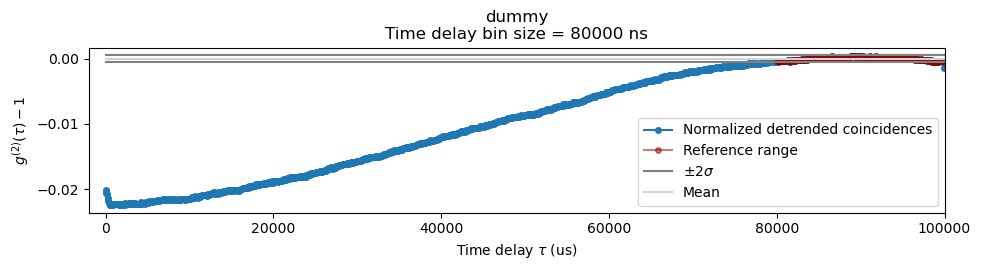

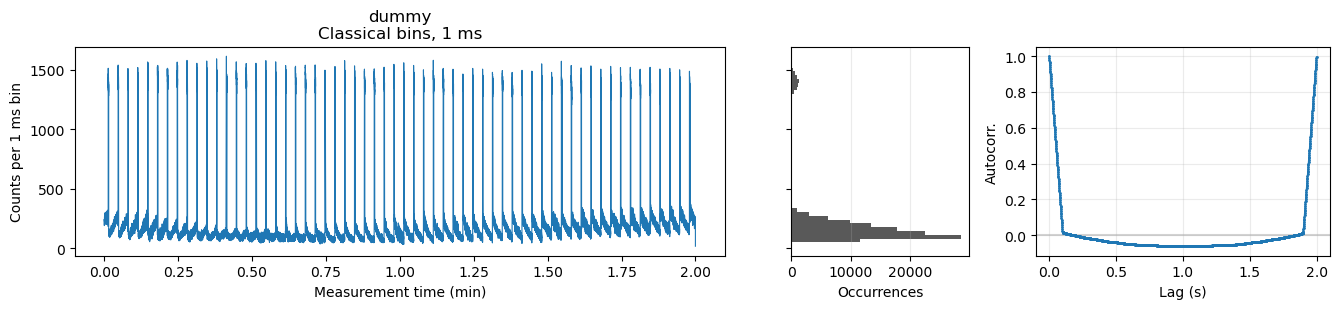

In [16]:
fitres_all = []


# Dataset selection
DATA_ROOT = Path(r"C:\Users\SSPDs\Documents\Offline SSPD Data")
DATASETS = [
    {
        "relative_folder": Path(r"20260602_testing"),
        "filename": "acq_11.b",
        "label": f"dummy",
    } ]


CORRELATION = {
    "delay_min_us": 0.08,
    "delay_max_us": 100_000,
    "bin_width_ps": 40e6,
    "correlation_mode": "A0",
    "worker_count": max(1, min(7, (os.cpu_count() or 8) - 1)),
    "decode_block_records": 10_000_000,
    "show_progress": True,
    "show_max_us":  100_000,
    "ref_range_us":np.array([80_000,100_000])
}
# Classical binning parameters
CLASSICAL = {
    "bin_width_ms": 1,
    "chunk_minutes": 2,
    "include_channels": None,      # None = all photon channels; or e.g. [0, 1]
    "force_recompute": False,
    "show_progress": True,
}



def dataset_path(dataset):
    return DATA_ROOT / dataset["relative_folder"] / dataset["filename"]

def correlate_dataset(dataset, params=CORRELATION):
    filepath = dataset_path(dataset)
    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(
        str(filepath),
        tau_min_us=params["delay_min_us"],
        tau_max_us=params["delay_max_us"],
        tau_bin_ps=params["bin_width_ps"],
        n_workers=params["worker_count"],
        mode=params["correlation_mode"],
        block_records=params["decode_block_records"],
        show_progress=params["show_progress"],
    )
    print(f"Finished correlating {n_records / 1e6:.3f} million records in file: {filepath}")
    print(f"Total {np.sum(hist) / 1e9:.6g} billion coincidences in histogram")
    return tau, hist, n_records



results = []
LOAD_EXISTING_CORRELATION = True   # False = recompute , True is "read existing"

for dataset in DATASETS:
    filepath = dataset_path(dataset)
    base = str(filepath.parent)
    histogram_name = filepath.name[:-2]  

    if LOAD_EXISTING_CORRELATION:
        hist, tau, params = analysis_cmd.read_existing(
            base,
            name=histogram_name,
            mode=CORRELATION["correlation_mode"],
        )
        n_records = None
        print(f"Loaded existing {CORRELATION['correlation_mode']} histogram: {filepath}")
    else:
        tau, hist, n_records = correlate_dataset(dataset, params=CORRELATION)

    results.append({"dataset": dataset, "tau": tau, "hist": hist, "n_records": n_records})

    latest = results[-1]
    rebin_plot(
        latest["tau"],
        latest["hist"],
        n_new_bins=1e3,
        ref_range_s=CORRELATION["ref_range_us"]*1e-6,
        x_limit_us=CORRELATION["show_max_us"],
        title=latest["dataset"].get("label", latest["dataset"]["filename"]),
        y_limit=None,#[-0.005,0.08]
    )

    filepath = dataset_path(dataset)

    classical_data = load_or_create_classical_bins(
        filepath,
        bin_width_ms=CLASSICAL["bin_width_ms"],
        chunk_minutes=CLASSICAL["chunk_minutes"],
        include_channels=CLASSICAL["include_channels"],
        force_recompute=CLASSICAL["force_recompute"],
        show_progress=CLASSICAL["show_progress"],
        
    )

    classical_plot = plot_classical_counts(
        classical_data,
        title=f"{dataset.get('label', dataset['filename'])}\n"
            f"Classical bins, {CLASSICAL['bin_width_ms']} ms",
        histogram_bins = 50,
        y_lims=None,#[0,600],
        ac_xlim_s = 2
    )


In [ ]:
analysis_setup()


------------------ LOG ------------------
PicoHarp analysis server reached.
[ANALYSIS - UTC 2026-05-08 16:15:42] Reading file with name _chunk0 in mode all from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PL\20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_2.9_LINSP
[ANALYSIS - UTC 2026-05-08 16:15:51] PicoHarp file C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PL\20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_2.9_LINSP\_chunk0.b: 67671164 records
mode=all, tau_min=0.08us, tau_max=20000us, bin=40000.0ps
ticks: min=20000, max=5000000000, bin=10000, nbins=499998
[decode]  14.8% (10000000/67671164) records

<Pyro4.core.Proxy at 0x12086a36700; connected IPv4; for PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9098>

[decode] 100.0% (67671164/67671164) records
Decoded 63826949 photons in 5.1s; overflow records=3844215; ch0=33340479, ch1=30486470
Selected mode=all: ref=63826949, stop=63826949; using 7 workers.
[correlate] 100.0% done, elapsed 166.6s ETA 0.0sss
Correlation done in 166.6s; coincidences=25275792187
Correlation done.
[ANALYSIS - UTC 2026-05-08 16:18:46] PicoHarp file C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PL\20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_3.0_LINSP\_chunk0.b: 59015052 records
mode=all, tau_min=0.08us, tau_max=20000us, bin=40000.0ps
ticks: min=20000, max=5000000000, bin=10000, nbins=499998
[decode] 100.0% (59015052/59015052) records
Decoded 54316567 photons in 4.1s; overflow records=4698485; ch0=28402956, ch1=25913611
Selected mode=all: ref=54316567, stop=54316567; using 7 workers.
[correlate] 100.0% done, elapsed 97.4s ETA 0.0sss
Correlation done in 97.4s; coincidences=15041821292
Correlation done.


[ANALYSIS - UTC 2026-05-08 16:20:29] PicoHarp file C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PL\20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_3.1_LINSP\_chunk0.b: 45386665 records
mode=all, tau_min=0.08us, tau_max=20000us, bin=40000.0ps
ticks: min=20000, max=5000000000, bin=10000, nbins=499998
[decode] 100.0% (45386665/45386665) records
Decoded 39833910 photons in 3.1s; overflow records=5552755; ch0=20865318, ch1=18968592
Selected mode=all: ref=39833910, stop=39833910; using 7 workers.
[correlate] 100.0% done, elapsed 46.2s ETA 0.0sss
Correlation done in 46.2s; coincidences=6918672824
Correlation done.
[ANALYSIS - UTC 2026-05-08 16:21:20] PicoHarp file C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PL\20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_3.3_LINSP\_chunk0.b: 39394031 records
mode=all, tau_min=0.08us, tau_max=20000us, bin=40000.0ps
ticks: min=20000, max=5000000000, bin=10000, nbins=499998
[decode] 100.0% (39394031/39394031) records
Decoded 265

C:\Users\SSPDs\AppData\Local\Temp\ipykernel_5260\3672835675.py:282: RuntimeWarning: overflow encountered in scalar subtract
  slope_guess = (h_rebin[-edge] - h_rebin[edge]) / (tau_rebin[-edge] - tau_rebin[edge]) / h_0


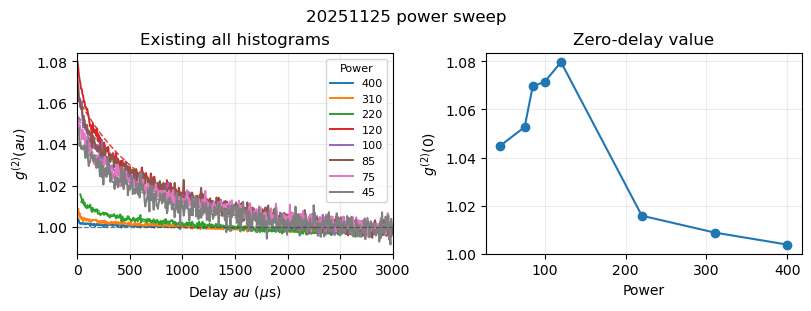

In [30]:
# Overlay existing g2 histograms for the 20251125 VOA power sweep
from lmfit import Model

POWER_SWEEP_VOAS = [2.9, 3.0, 3.1, 3.3, 3.35, 3.4, 3.45, 3.5]
POWER_SWEEP_POWERS = np.array([400, 310, 220, 120, 100, 85, 75, 45], dtype=float)

POWER_SWEEP_ROOT = Path(r"C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PL")
POWER_SWEEP_DATASETS = [
    {
        "relative_folder": Path(r"20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP") / f"VOA_{voa}_LINSP",
        "filename": "_chunk0.b",
        "label": f"VOA = {voa} V",
        "voa": voa,
        "power": power,
    }
    for voa, power in zip(POWER_SWEEP_VOAS, POWER_SWEEP_POWERS)
]

POWER_SWEEP_MODE = CORRELATION.get("correlation_mode", "X01")
POWER_SWEEP_MAX_DELAY_US = 3000
POWER_SWEEP_FIT_MIN_US = 0
POWER_SWEEP_FIT_MAX_US = 3000
POWER_SWEEP_INITIAL_LIFETIME_US = 300
POWER_SWEEP_REF_RANGE_S = tuple(
    np.asarray(CORRELATION.get("ref_range_us", np.array([3000, 10000])), dtype=float) * 1e-6
)
POWER_SWEEP_REBIN_BINS = 3000


def single_exp(tau_us, amplitude, lifetime_us):
    return amplitude * np.exp(-tau_us / lifetime_us)


power_sweep_exp_model = Model(single_exp)
power_sweep_summary = []
fig, (ax_g2, ax_g2_zero) = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)

for dataset in POWER_SWEEP_DATASETS:
    filepath = POWER_SWEEP_ROOT / dataset["relative_folder"] / dataset["filename"]
    hist, tau, params = analysis_cmd.read_existing(
        str(filepath.parent),
        name=filepath.name[:-2],
        mode=POWER_SWEEP_MODE,
    )

    tau_rebin, hist_detrended, hist_std, hist_baseline = g2izer(
        tau,
        hist,
        n_new_bins=POWER_SWEEP_REBIN_BINS,
        ref_range_s=POWER_SWEEP_REF_RANGE_S,
        verbose=False,
    )
    g2_minus_1 = hist_detrended / hist_baseline
    g2 = 1.0 + g2_minus_1
    tau_us = tau_rebin * 1e6
    plot_mask = tau_us <= POWER_SWEEP_MAX_DELAY_US
    fit_mask = (
        (tau_us >= POWER_SWEEP_FIT_MIN_US)
        & (tau_us <= POWER_SWEEP_FIT_MAX_US)
        & np.isfinite(g2_minus_1)
    )
    zero_idx = my_find_nearest(tau_rebin, 0.0)
    g2_zero = float(g2[zero_idx])

    line, = ax_g2.plot(
        tau_us[plot_mask],
        g2[plot_mask],
        linewidth=1.4,
        label=f"{dataset['power']:g}",
    )

    fit_result = None
    lifetime_us = np.nan
    if np.count_nonzero(fit_mask) >= 4:
        fit_params = power_sweep_exp_model.make_params(
            amplitude=float(g2_minus_1[fit_mask][0]),
            lifetime_us=POWER_SWEEP_INITIAL_LIFETIME_US,
        )
        fit_params["lifetime_us"].set(min=1e-9)
        fit_result = power_sweep_exp_model.fit(
            g2_minus_1[fit_mask],
            fit_params,
            tau_us=tau_us[fit_mask],
        )
        lifetime_us = float(fit_result.params["lifetime_us"].value)
        ax_g2.plot(
            tau_us[fit_mask],
            1.0 + fit_result.best_fit,
            "--",
            color=line.get_color(),
            linewidth=1.1,
            alpha=0.85,
        )

    power_sweep_summary.append(
        {
            "dataset": dataset,
            "filepath": filepath,
            "tau": tau_rebin,
            "g2": g2,
            "g2_minus_1": g2_minus_1,
            "g2_zero": g2_zero,
            "lifetime_us": lifetime_us,
            "fit_result": fit_result,
            "hist_std": hist_std,
            "hist_baseline": hist_baseline,
            "params": params,
        }
    )

powers = np.array([item["dataset"]["power"] for item in power_sweep_summary], dtype=float)
g2_zero = np.array([item["g2_zero"] for item in power_sweep_summary], dtype=float)
power_sweep_lifetime_us = np.array([item["lifetime_us"] for item in power_sweep_summary], dtype=float)
order = np.argsort(powers)

ax_g2.axhline(1.0, color="0.25", linestyle="--", linewidth=0.9, alpha=0.7)
ax_g2.set_xlim(0, POWER_SWEEP_MAX_DELAY_US)
ax_g2.set_xlabel(r"Delay $	au$ ($\mu$s)")
ax_g2.set_ylabel(r"$g^{(2)}(	au)$")
ax_g2.set_title(f"Existing {POWER_SWEEP_MODE} histograms")
ax_g2.legend(title="Power", fontsize=8, title_fontsize=8)
ax_g2.grid(True, alpha=0.25)

ax_g2_zero.plot(powers[order], g2_zero[order], "o-", linewidth=1.5, label=r"$g^{(2)}(0)$")
ax_g2_zero.set_xlabel("Power")
ax_g2_zero.set_ylabel(r"$g^{(2)}(0)$")
ax_g2_zero.set_title(r"Zero-delay value")
ax_g2_zero.grid(True, alpha=0.25)

fig.suptitle("20251125 power sweep")
power_sweep_fig = fig


Text(0, 0.5, 'Lifetime from exp. fit (us)')

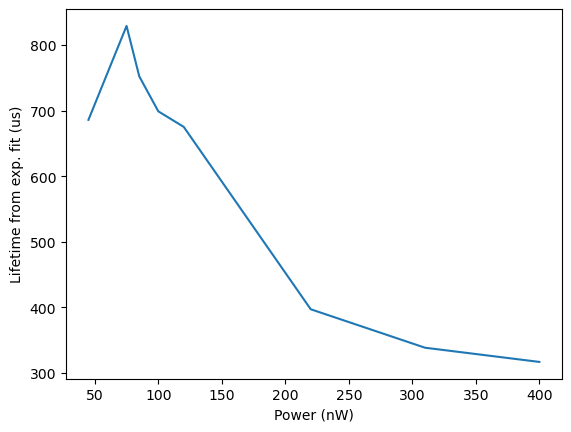

In [33]:
plt.plot(powers, power_sweep_lifetime_us)
plt.xlabel("Power (nW)")
plt.ylabel("Lifetime from exp. fit (us)")